In [1]:
# SPDX-FileCopyrightText: 2025 Contributors to the OpenSTEF project <openstef@lfenergy.org>
#
# SPDX-License-Identifier: MPL-2.0

# School Holidays and a Christmas Forecast

Does adding school holidays as a feature change a forecast over the Christmas break?
This tutorial trains two GBLinear models on the same data. One uses school holiday
features and one does not. Both forecast the week of 21 December 2024, which falls
in the Christmas school holiday for the Noord-Holland region.

**What you'll learn:**

- Export school holidays once to CSV with `SchoolHolidayFeatureAdder.export_csv`
- Enable school holiday features with `SchoolHolidayConfig` on a workflow
- Compare two forecasts side by side and measure whether the feature changes them

```{note}
This is a single feeder over a short training window, so the result is one
data point and not a general conclusion. The training window contains one school
holiday period (autumn, 26 October to 3 November 2024).
```

**Data attribution:** School holiday data from the
[OpenHolidays API](https://openholidaysapi.org), licensed under ODbL 1.0.
Commercial use is permitted with attribution.

In [2]:
import warnings

warnings.filterwarnings("ignore")

from openstef_core.testing import configure_notebook_display, setup_notebook_logging

configure_notebook_display()
logger = setup_notebook_logging(
    __name__,
    suppress=(
        "choreographer",
        "kaleido",
        "httpx",
        "huggingface_hub",
        "fsspec",
        "filelock",
        "openstef_core.datasets",
    ),
)

## Load the dataset and define the windows

We use the Liander 2024 dataset, the same as the
{doc}`/tutorials/forecasting_quickstart`, but a different feeder. Feeders serve
different customers, so a school holiday affects them differently. We picked
Watergraafsmeer because its load dips most during the autumn holiday in the training
window (about 16%, versus about 6% to 11% for most feeders). It is in Amsterdam,
which is in the Noord-Holland school holiday region we configure below.

- **Training:** 15 September to 21 December 2024. It includes the autumn school
  holiday (26 October to 3 November).
- **Forecast:** 21 to 28 December 2024, inside the Christmas school holiday.

The predict window includes 14 days of history before the forecast start for lag features.

In [3]:
from datetime import datetime, timedelta

import pandas as pd

from openstef_core.testing import load_liander_dataset

dataset = load_liander_dataset(target="mv_feeder/OS Watergraafsmeer")

train_start = datetime.fromisoformat("2024-09-15T00:00:00Z")
forecast_start = datetime.fromisoformat("2024-12-21T00:00:00Z")
forecast_end = forecast_start + timedelta(days=7)

train_dataset = dataset.filter_by_range(start=train_start, end=forecast_start)
predict_dataset = dataset.filter_by_range(
    start=forecast_start - timedelta(days=14),
    end=forecast_end,
)

print(
    f"Training:  {train_dataset.data.shape[0]:,} rows, "
    f"{train_dataset.data.index.min():%Y-%m-%d} to {train_dataset.data.index.max():%Y-%m-%d}"
)
print(
    f"Predict:   {predict_dataset.data.shape[0]:,} rows, "
    f"{predict_dataset.data.index.min():%Y-%m-%d} to {predict_dataset.data.index.max():%Y-%m-%d}"
)

Training:  9,312 rows, 2024-09-15 to 2024-12-20
Predict:   2,016 rows, 2024-12-07 to 2024-12-27


## Export the school holidays once

The OpenHolidays API is free and public, so we ask it for one range of dates in one
request and save the result to CSV. Workflows then read that file during `fit`, so
neither training nor forecasting calls the API again. The file is cached in the
system temp directory and is only requested if it is missing.

The range covers the training window and the forecast window, with a margin on each side.

In [4]:
import tempfile
from datetime import date
from pathlib import Path

from openstef_models.transforms.time_domain import SchoolHolidayConfig, SchoolHolidayFeatureAdder

csv_path = Path(tempfile.gettempdir()) / "openstef_school_holidays_nl_nh_2024_2025.csv"
if not csv_path.exists():
    SchoolHolidayFeatureAdder(country_code="NL", subdivision_code="NL-NH").export_csv(
        csv_path, start=date(2024, 1, 1), end=date(2025, 12, 31)
    )

holidays = SchoolHolidayFeatureAdder.from_csv(csv_path, country_code="NL", subdivision_code="NL-NH")
for period in holidays.holidays:
    if period.end_date >= date(2024, 9, 1) and period.start_date <= date(2025, 1, 10):
        print(f"{period.name}: {period.start_date} to {period.end_date}")

Summer Holidays: 2024-07-20 to 2024-09-01
Autumn Holidays: 2024-10-26 to 2024-11-03
Christmas Holidays: 2024-12-21 to 2025-01-05


## Configure the two workflows

Both workflows use the same GBLinear configuration. The only difference is
`school_holidays`. The baseline leaves it unset, and the holiday model sets it to a
[`SchoolHolidayConfig`](https://openstef.github.io/openstef/api/generated/openstef_models.transforms.time_domain.SchoolHolidayConfig.html)
that reads the CSV above.

In [5]:
from openstef_core.types import LeadTime, Q
from openstef_models.presets import ForecastingWorkflowConfig, create_forecasting_workflow
from openstef_models.presets.forecasting_workflow import GBLinearForecaster
from openstef_models.workflows import CustomForecastingWorkflow


def build_workflow(
    model_id: str, school_holidays: SchoolHolidayConfig | None, random_state: int = 0
) -> CustomForecastingWorkflow:
    # coord_descent is deterministic for a given seed. The default shotgun updater is not.
    return create_forecasting_workflow(
        config=ForecastingWorkflowConfig(
            model_id=model_id,
            model="gblinear",
            horizons=[LeadTime.from_string("PT36H")],
            quantiles=[Q(0.5), Q(0.1), Q(0.9)],
            target_column="load",
            temperature_column="temperature_2m",
            relative_humidity_column="relative_humidity_2m",
            wind_speed_column="wind_speed_10m",
            radiation_column="shortwave_radiation",
            pressure_column="surface_pressure",
            school_holidays=school_holidays,
            verbosity=0,
            mlflow_storage=None,
            gblinear_hyperparams=GBLinearForecaster.HyperParams(
                n_steps=50, updater="coord_descent", random_state=random_state
            ),
        )
    )


holiday_config = SchoolHolidayConfig(country_code="NL", subdivision_code="NL-NH", csv_path=csv_path)
baseline_workflow = build_workflow("christmas_gblinear_baseline", school_holidays=None)
holiday_workflow = build_workflow("christmas_gblinear_school_holidays", school_holidays=holiday_config)

2026/11/13 15:57:23 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/egor.dmitriev/projects/opensource/openstef-cocoding/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Train both models

Both models are fit on the same training data. The holiday model reads the CSV during
`fit`, so the holiday feature set is fixed in the checkpoint.

In [6]:
baseline_result = baseline_workflow.fit(train_dataset)
holiday_result = holiday_workflow.fit(train_dataset)

for name, result in [("Baseline", baseline_result), ("School holidays", holiday_result)]:
    if result is not None and result.metrics_test is not None:
        print(f"{name} test-set metrics:")
        print(result.metrics_test.to_dataframe())

[2026-11-13 15:57:23,972][INFO] lag fallback applied


[2026-11-13 15:57:24,254][INFO] lag fallback applied


[2026-11-13 15:57:25,344][INFO] lag fallback applied


[2026-11-13 15:57:25,630][INFO] lag fallback applied


[2026-11-13 15:57:25,728][INFO] lag fallback applied


[2026-11-13 15:57:26,841][INFO] lag fallback applied


In [7]:
assert baseline_result is not None, "Baseline training should produce a result"
assert holiday_result is not None, "School holiday training should produce a result"

## Forecast the Christmas week

Each model forecasts the same seven days, starting on the first day of the Christmas break.

In [8]:
from openstef_core.datasets import ForecastDataset

baseline_forecast: ForecastDataset = baseline_workflow.predict(predict_dataset, forecast_start=forecast_start)
holiday_forecast: ForecastDataset = holiday_workflow.predict(predict_dataset, forecast_start=forecast_start)

print(f"Baseline rows: {len(baseline_forecast.data)}, school holiday rows: {len(holiday_forecast.data)}")

Baseline rows: 672, school holiday rows: 672


In [9]:
assert len(baseline_forecast.data) > 100, "Baseline forecast should have many rows"
assert len(holiday_forecast.data) > 100, "School holiday forecast should have many rows"

## Compare the two forecasts

We score both forecasts against the measured load with two metrics from openstef-beam:

- **rMAE** scores the median forecast. It is the mean absolute error divided by the range
  of the measured load in the window.
- **rCRPS** scores all quantiles together. It is the continuous ranked probability score
  divided by the same range.

Both are scale-free, and lower is better. Both models share the same measured load, so the
normalizer is identical and the two scores compare directly. The difference between the two
forecasts shows how much the holiday feature moves the prediction.

In [10]:
from openstef_beam.metrics import rcrps, rmae

actual = predict_dataset.data["load"].loc[forecast_start:forecast_end].rename("actual")
baseline_median = baseline_forecast.median_series.rename("baseline")
holiday_median = holiday_forecast.median_series.rename("school_holidays")

# The Liander feeder stores load in watts, so convert to kilowatts for display.
comparison = pd.concat([actual, baseline_median, holiday_median], axis=1).dropna() / 1000
comparison["difference"] = comparison["school_holidays"] - comparison["baseline"]


def score(forecast: ForecastDataset, actual: pd.Series) -> dict[str, float]:
    quantiles = sorted(forecast.quantiles)
    columns = [quantile.format() for quantile in quantiles]
    aligned = pd.concat([actual, forecast.data[columns]], axis=1).dropna()
    return {
        "rMAE": rmae(aligned["actual"].to_numpy(), aligned[Q(0.5).format()].to_numpy()),
        "rCRPS": rcrps(aligned["actual"].to_numpy(), aligned[columns].to_numpy(), quantiles),
    }


summary = pd.DataFrame(
    {
        "Baseline": score(baseline_forecast, actual),
        "School holidays": score(holiday_forecast, actual),
    }
).T
print(f"Compared rows: {len(comparison)}")
print(summary.round(4).to_string())
print(f"\nMean difference, school holidays minus baseline: {comparison['difference'].mean():.3f} kW")
print(f"Mean absolute difference between the two forecasts: {comparison['difference'].abs().mean():.3f} kW")
print(f"Largest absolute difference: {comparison['difference'].abs().max():.3f} kW")

Compared rows: 672
                   rMAE   rCRPS
Baseline         0.3324  0.2426
School holidays  0.2780  0.2088

Mean difference, school holidays minus baseline: -54.685 kW
Mean absolute difference between the two forecasts: 54.685 kW
Largest absolute difference: 72.076 kW


## Visualize the comparison

The top panel shows the measured load and both median forecasts. The bottom panel shows
the difference, school holidays minus baseline.

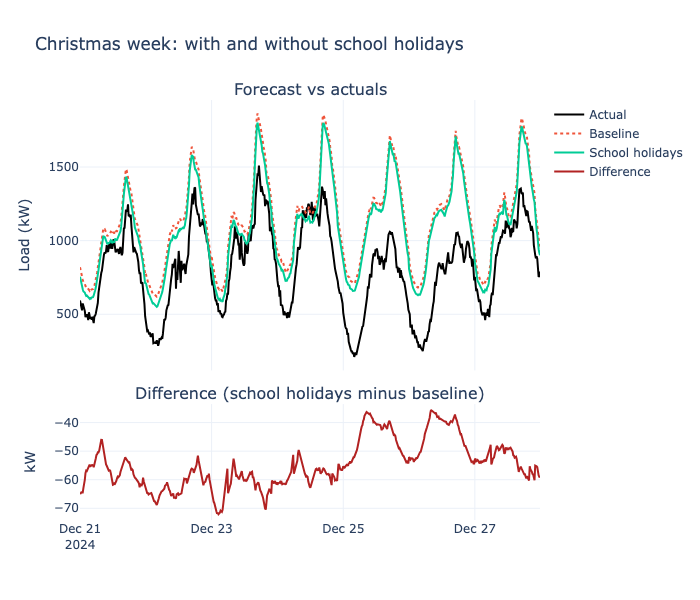

In [11]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    row_heights=[0.7, 0.3],
    subplot_titles=("Forecast vs actuals", "Difference (school holidays minus baseline)"),
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["actual"], name="Actual", line={"color": "black"}), row=1, col=1
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["baseline"], name="Baseline", line={"dash": "dot"}), row=1, col=1
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["school_holidays"], name="School holidays"),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["difference"], name="Difference", line={"color": "firebrick"}),
    row=2,
    col=1,
)
fig.update_layout(height=600, template="plotly_white", title="Christmas week: with and without school holidays")
fig.update_yaxes(title_text="Load (kW)", row=1, col=1)
fig.update_yaxes(title_text="kW", row=2, col=1)
fig.show()

## Is the difference more than noise?

A single fit can differ from another only because of its random seed. We refit both
variants for five seeds, using the same seed for the baseline and the holiday model so each
pair differs only in the school-holiday features. The spread of the paired difference across
seeds shows how much of the gain is run variance.

In [12]:
import numpy as np

fit_rows = []
for seed in range(5):
    row: dict[str, float] = {"seed": seed}
    for label, school_holidays in [("baseline", None), ("school_holidays", holiday_config)]:
        workflow = build_workflow(f"christmas_gblinear_{label}_seed{seed}", school_holidays, random_state=seed)
        workflow.fit(train_dataset)
        for metric, value in score(workflow.predict(predict_dataset, forecast_start=forecast_start), actual).items():
            row[f"{label}_{metric}"] = value
    fit_rows.append(row)

fit_results = pd.DataFrame(fit_rows)
for metric in ["rMAE", "rCRPS"]:
    fit_results[f"{metric}_difference"] = fit_results[f"school_holidays_{metric}"] - fit_results[f"baseline_{metric}"]
print(fit_results.round(4).to_string(index=False))
print()
for metric in ["rMAE", "rCRPS"]:
    difference = fit_results[f"{metric}_difference"]
    print(
        f"{metric} difference (school holidays minus baseline): "
        f"mean {difference.mean():.4f}, std {difference.std():.4f}"
    )

[2026-11-13 15:57:30,036][INFO] lag fallback applied


[2026-11-13 15:57:30,139][INFO] lag fallback applied


[2026-11-13 15:57:31,302][INFO] lag fallback applied


[2026-11-13 15:57:31,644][INFO] lag fallback applied


[2026-11-13 15:57:31,746][INFO] lag fallback applied


[2026-11-13 15:57:33,253][INFO] lag fallback applied


... (21 outputs left out)

[2026-11-13 15:57:45,106][INFO] lag fallback applied


[2026-11-13 15:57:45,200][INFO] lag fallback applied


[2026-11-13 15:57:46,450][INFO] lag fallback applied


 seed  baseline_rMAE  baseline_rCRPS  school_holidays_rMAE  school_holidays_rCRPS  rMAE_difference  rCRPS_difference
    0         0.3324          0.2426                0.2780                 0.2088          -0.0544           -0.0339
    1         0.3308          0.2410                0.2707                 0.2032          -0.0601           -0.0378
    2         0.3314          0.2411                0.2722                 0.2047          -0.0591           -0.0365
    3         0.3301          0.2405                0.2700                 0.2029          -0.0600           -0.0376
    4         0.3327          0.2425                0.2724                 0.2046          -0.0603           -0.0379

rMAE difference (school holidays minus baseline): mean -0.0588, std 0.0025
rCRPS difference (school holidays minus baseline): mean -0.0367, std 0.0017


In [13]:
assert len(fit_results) == 5, "Expected one row per seed"
assert np.isfinite(fit_results.drop(columns="seed").to_numpy()).all(), "Metric values should be finite"

## Placebo: a normal school week

If the gain above comes from the holiday, it should not appear in a week with no holiday.
We retrain both models on data up to 9 December 2024 and forecast 9 to 16 December, a normal
school week. Training still includes the autumn holiday, but not the Christmas one. We run the
same five paired seeds.

In [14]:
placebo_start = datetime.fromisoformat("2024-12-09T00:00:00Z")
placebo_end = placebo_start + timedelta(days=7)
placebo_train = dataset.filter_by_range(start=train_start, end=placebo_start)
placebo_predict = dataset.filter_by_range(start=placebo_start - timedelta(days=14), end=placebo_end)
placebo_actual = placebo_predict.data["load"].loc[placebo_start:placebo_end].rename("actual")

placebo_rows = []
for seed in range(5):
    row: dict[str, float] = {"seed": seed}
    for label, school_holidays in [("baseline", None), ("school_holidays", holiday_config)]:
        workflow = build_workflow(f"placebo_gblinear_{label}_seed{seed}", school_holidays, random_state=seed)
        workflow.fit(placebo_train)
        forecast = workflow.predict(placebo_predict, forecast_start=placebo_start)
        for metric, value in score(forecast, placebo_actual).items():
            row[f"{label}_{metric}"] = value
    placebo_rows.append(row)

placebo_results = pd.DataFrame(placebo_rows)
for metric in ["rMAE", "rCRPS"]:
    placebo_results[f"{metric}_difference"] = (
        placebo_results[f"school_holidays_{metric}"] - placebo_results[f"baseline_{metric}"]
    )
print(placebo_results.round(4).to_string(index=False))
print()
for metric in ["rMAE", "rCRPS"]:
    difference = placebo_results[f"{metric}_difference"]
    print(
        f"{metric} difference, normal week (school holidays minus baseline): "
        f"mean {difference.mean():.4f}, std {difference.std():.4f}, "
        f"school holidays better in {(difference < 0).sum()} of {len(difference)} fits"
    )

[2026-11-13 15:57:46,798][INFO] lag fallback applied


[2026-11-13 15:57:46,883][INFO] lag fallback applied


[2026-11-13 15:57:47,920][INFO] lag fallback applied


[2026-11-13 15:57:48,225][INFO] lag fallback applied


[2026-11-13 15:57:48,314][INFO] lag fallback applied


[2026-11-13 15:57:49,375][INFO] lag fallback applied


... (21 outputs left out)

[2026-11-13 15:58:00,256][INFO] lag fallback applied


[2026-11-13 15:58:00,341][INFO] lag fallback applied


[2026-11-13 15:58:01,508][INFO] lag fallback applied


 seed  baseline_rMAE  baseline_rCRPS  school_holidays_rMAE  school_holidays_rCRPS  rMAE_difference  rCRPS_difference
    0         0.2706          0.1523                0.2744                 0.1540           0.0037            0.0016
    1         0.2689          0.1521                0.2714                 0.1531           0.0025            0.0010
    2         0.2696          0.1518                0.2731                 0.1538           0.0035            0.0020
    3         0.2682          0.1512                0.2724                 0.1538           0.0042            0.0026
    4         0.2711          0.1529                0.2729                 0.1541           0.0018            0.0012

rMAE difference, normal week (school holidays minus baseline): mean 0.0031, std 0.0010, school holidays better in 0 of 5 fits
rCRPS difference, normal week (school holidays minus baseline): mean 0.0017, std 0.0006, school holidays better in 0 of 5 fits


In [15]:
assert len(placebo_results) == 5, "Expected one row per placebo seed"
assert np.isfinite(placebo_results.drop(columns="seed").to_numpy()).all(), "Placebo metric values should be finite"

## Regional groups when the region is unknown

Choosing `NL-NH` assumes we know the region of the feeder. When that is not known, set
`regional_groups=True`. The transform then adds one 0/1 column per group of subdivisions that
share a holiday calendar, and the model learns which group matters for this feeder. Columns are
numbered by the sorted subdivision codes of each group, so the numbering is stable across runs. The
file below holds all Dutch subdivisions, from one cached request.

In [16]:
regional_csv_path = Path(tempfile.gettempdir()) / "openstef_school_holidays_nl_regional_2024_2025.csv"
if not regional_csv_path.exists():
    SchoolHolidayFeatureAdder(country_code="NL", regional_groups=True).export_csv(
        regional_csv_path, start=date(2024, 1, 1), end=date(2025, 12, 31)
    )

regional_holidays = SchoolHolidayFeatureAdder.from_csv(regional_csv_path, country_code="NL", regional_groups=True)
group_members = {
    period.group_code: period.subdivisions for period in regional_holidays.holidays if period.group_code is not None
}
for code in sorted(group_members, key=int):
    print(f"is_school_holiday_{code}: {len(group_members[code])} subdivisions {group_members[code][:6]}")

is_school_holiday_0: 126 subdivisions ['NL-DR', 'NL-DR-AH', 'NL-DR-AS', 'NL-DR-BO', 'NL-DR-CO', 'NL-DR-DW']
is_school_holiday_1: 112 subdivisions ['NL-FL', 'NL-FL-ZE', 'NL-GE', 'NL-GE-AA', 'NL-GE-AP', 'NL-GE-BA']
is_school_holiday_2: 127 subdivisions ['NL-GE', 'NL-GE-AR', 'NL-GE-BD', 'NL-GE-BE', 'NL-GE-DB', 'NL-GE-DR']


We fit one regional model and compare it with the baseline and the `NL-NH` model on the
Christmas week.

In [17]:
regional_config = SchoolHolidayConfig(country_code="NL", regional_groups=True, csv_path=regional_csv_path)
regional_workflow = build_workflow("christmas_gblinear_regional", school_holidays=regional_config)
regional_workflow.fit(train_dataset)
regional_forecast: ForecastDataset = regional_workflow.predict(predict_dataset, forecast_start=forecast_start)

regional_summary = pd.DataFrame(
    {
        "Baseline": score(baseline_forecast, actual),
        "NL-NH holidays": score(holiday_forecast, actual),
        "Regional groups": score(regional_forecast, actual),
    }
).T
print(regional_summary.round(4).to_string())

[2026-11-13 15:58:01,842][INFO] lag fallback applied


[2026-11-13 15:58:01,953][INFO] lag fallback applied


[2026-11-13 15:58:03,201][INFO] lag fallback applied


                   rMAE   rCRPS
Baseline         0.3324  0.2426
NL-NH holidays   0.2780  0.2088
Regional groups  0.2768  0.2095


To check that this is not noise, we repeat the regional fit for the same five seeds and compare
each fit with the baseline fit that used the same seed in the variance check above.

In [18]:
regional_rows = []
for seed in range(5):
    workflow = build_workflow(f"christmas_gblinear_regional_seed{seed}", regional_config, random_state=seed)
    workflow.fit(train_dataset)
    row: dict[str, float] = {"seed": seed}
    for metric, value in score(workflow.predict(predict_dataset, forecast_start=forecast_start), actual).items():
        row[f"regional_{metric}"] = value
    regional_rows.append(row)

regional_fits = fit_results[["seed", "baseline_rMAE", "baseline_rCRPS"]].merge(pd.DataFrame(regional_rows), on="seed")
for metric in ["rMAE", "rCRPS"]:
    regional_fits[f"{metric}_difference"] = regional_fits[f"regional_{metric}"] - regional_fits[f"baseline_{metric}"]
print(regional_fits.round(4).to_string(index=False))
print()
for metric in ["rMAE", "rCRPS"]:
    difference = regional_fits[f"{metric}_difference"]
    print(
        f"{metric} difference (regional groups minus baseline): "
        f"mean {difference.mean():.4f}, std {difference.std():.4f}, "
        f"regional better in {(difference < 0).sum()} of {len(difference)} fits"
    )

[2026-11-13 15:58:03,759][INFO] lag fallback applied


[2026-11-13 15:58:03,856][INFO] lag fallback applied


[2026-11-13 15:58:05,119][INFO] lag fallback applied


[2026-11-13 15:58:05,448][INFO] lag fallback applied


[2026-11-13 15:58:05,540][INFO] lag fallback applied


[2026-11-13 15:58:06,691][INFO] lag fallback applied


... (6 outputs left out)

[2026-11-13 15:58:10,117][INFO] lag fallback applied


[2026-11-13 15:58:10,209][INFO] lag fallback applied


[2026-11-13 15:58:11,334][INFO] lag fallback applied


 seed  baseline_rMAE  baseline_rCRPS  regional_rMAE  regional_rCRPS  rMAE_difference  rCRPS_difference
    0         0.3324          0.2426         0.2768          0.2095          -0.0557           -0.0331
    1         0.3308          0.2410         0.2746          0.2078          -0.0562           -0.0332
    2         0.3314          0.2411         0.2727          0.2069          -0.0587           -0.0343
    3         0.3301          0.2405         0.2703          0.2048          -0.0598           -0.0357
    4         0.3327          0.2425         0.2746          0.2075          -0.0582           -0.0350

rMAE difference (regional groups minus baseline): mean -0.0577, std 0.0017, regional better in 5 of 5 fits
rCRPS difference (regional groups minus baseline): mean -0.0342, std 0.0011, regional better in 5 of 5 fits


In [19]:
assert len(regional_fits) == 5, "Expected one row per regional seed"
assert np.isfinite(regional_fits.drop(columns="seed").to_numpy()).all(), "Regional metric values should be finite"

# - **In the Christmas week, the holiday feature helps.** The school-holiday forecast has a lower
#   rMAE (about 0.278 against 0.332) and rCRPS (about 0.209 against 0.243) than the baseline. Across
#   five paired seeds, the holiday variant was better on both metrics every time. The mean rMAE
#   gap was about 0.059.
# - **Regional groups recover most of the gain without picking a province.** On seed 0, the
#   regional model scores about the same as the `NL-NH` model: rMAE 0.277 against 0.278 and
#   rCRPS 0.210 against 0.209. Across the five seeds, the regional gain over the baseline is
#   about 0.001 smaller in rMAE (-0.058 against -0.059) and about 0.0025 smaller in rCRPS (-0.034
#   against -0.037). The regional model beat the baseline on both metrics in all five seeds. This
#   feeder is one case, so do not read it as a general rule.
# - **In a normal school week, the holiday feature hurts a little.** In the placebo week, the
#   holiday variant has a higher rMAE (mean difference about +0.003) and rCRPS (about +0.002). It
#   was worse in all five seeds. The gap is small but consistent in sign, so the Christmas gain is
#   not a general improvement from extra features.
# - **Run-to-run noise is small compared with both effects.** The seed-to-seed standard deviation
#   of the paired rMAE difference is about 0.0025 in the Christmas week and about 0.0010 in the
#   placebo week. The Christmas effect (about 0.059) is far larger than that spread. The placebo
#   effect (about 0.003) is about three standard deviations, so it is consistent but small. The
#   notebook uses `coord_descent`, which is deterministic for a fixed seed, so re-running it gives
#   the same numbers. The default `shotgun` updater is not used here.
# - **The baseline misses the holiday drop.** In the Christmas week, the school-holiday forecast
#   sits on average about 55 kW below the baseline, with a largest gap of over 70 kW. The
#   baseline has no information about when the holiday starts, so this gap is consistent with the
#   feature capturing the Christmas drop. This notebook does not isolate that cause.
#
# The trade-off is clear on this feeder: the feature gains a lot in a holiday week and loses a
# little in a normal week. Whether that is worth it depends on how often holidays fall in the
# forecast horizon. This is one feeder, one holiday period in training, and one forecast week
# for each case. The feeder was chosen from training-window data before the comparison was run.
# Other feeders can respond differently, so test more holidays and feeders before you choose a
# default.

## Next steps

- {doc}`/tutorials/feature_engineering` — the school holiday transform and the
  one-hot option for each holiday name.
- {doc}`/tutorials/forecasting_quickstart` — the baseline workflow without holidays.